In [1]:
# Лекция 1

# Часть 1

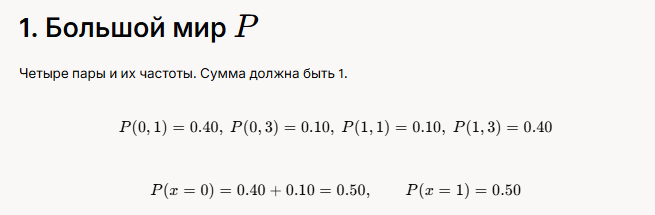

In [3]:
import numpy as np
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import train_test_split
from sklearn.dummy import DummyRegressor
from sklearn.tree import DecisionTreeRegressor

In [53]:
pairs = np.array([[0, 1], [0, 3], [1, 1], [1, 3]])

In [54]:
probs = np.array([0.40, 0.10, 0.10, 0.40])

In [6]:
assert np.isclose(probs.sum(), 1.0)

In [7]:
P_x0 = probs[0] + probs[1]

In [8]:
P_x1 = probs[2] + probs[3]

In [9]:
print(P_x0, P_x1)

0.5 0.5


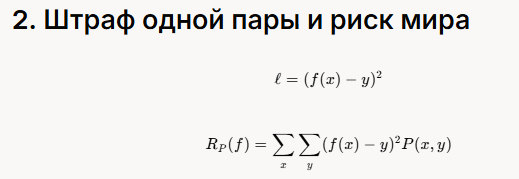

In [80]:
def f_A(x):
    return np.full_like(x, 2.0, dtype=float) # f_A(0)=f_A(1)=2

In [81]:
def f_B(x):
    return np.where(x == 0, 1.0, 3.0) # f_B(0)=1, f_B(1)=3

In [82]:
def f_star(x):
    return np.where(x == 0, 1.4, 2.6) # E[Y|x], оптимум MSE

In [83]:
def risk_P(f):
    # R_P(f) = Σ (f(x)-y)^2 P(x,y) по 4 атомам
    pred = f(pairs[:, 0])
    loss = (pred - pairs[:, 1]) ** 2 # ℓ = (f(x)-y)^2
    return np.sum(loss * probs)

In [84]:
print(risk_P(f_A), risk_P(f_B), risk_P(f_star))

1.0 0.8 0.64


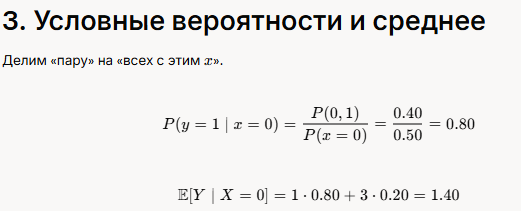

In [92]:
P_y1_x0 = probs[0] / P_x0 # 0.40 / 0.50 = 0.80
P_y3_x0 = probs[1] / P_x0 # 0.10 / 0.50 = 0.20
E_y_x0 = 1 * P_y1_x0 + 3 * P_y3_x0 # 1.40

In [93]:
P_y1_x1 = probs[2] / P_x1 # 0.10 / 0.50 = 0.20
P_y3_x1 = probs[3] / P_x1 # 0.40 / 0.50 = 0.80
E_y_x1 = 1 * P_y1_x1 + 3 * P_y3_x1 # 2.60

In [94]:
print(E_y_x0, E_y_x1)

1.4000000000000001 2.6000000000000005


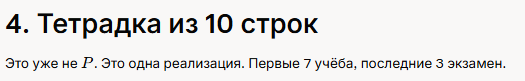

In [96]:
X = np.array([0, 1, 0, 1, 1, 0, 1, 0, 1, 0])
y = np.array([1, 3, 1, 3, 3, 1, 1, 3, 3, 1], dtype=float)

In [97]:
# A_train = {0..6}, A_test = {7,8,9}   (в коде с нуля)
X_train, y_train = X[:7], y[:7]
X_test,  y_test  = X[7:], y[7:]
print(len(y_train), len(y_test))  # 7 и 3

7 3


In [99]:
# так обычно режут в жизни, здесь не используем чтобы совпали цифры лекции
# X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.3, random_state=0)

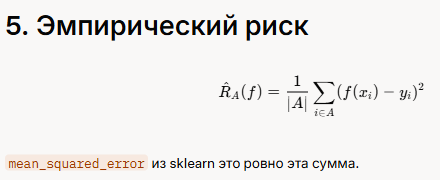

In [102]:
def R_hat(f, Xa, ya):
    # (1/|A|) Σ (f(x_i)-y_i)^2
    return mean_squared_error(ya, f(Xa))

print("train A", R_hat(f_A, X_train, y_train))  # 7/7 = 1
print("train B", R_hat(f_B, X_train, y_train))  # 4/7 ≈ 0.571
print("test  A", R_hat(f_A, X_test,  y_test))   # 3/3 = 1
print("test  B", R_hat(f_B, X_test,  y_test))   # 4/3 ≈ 1.333

train A 1.0
train B 0.5714285714285714
test  A 1.0
test  B 1.3333333333333333


In [101]:
pred_B_train = f_B(X_train) # [1,3,1,3,3,1,3]
loss_B_train = (pred_B_train - y_train)**2 # [0,0,0,0,0,0,4]
print(loss_B_train, loss_B_train.mean()) # сумма 4, среднее 4/7

[0. 0. 0. 0. 0. 0. 4.] 0.5714285714285714


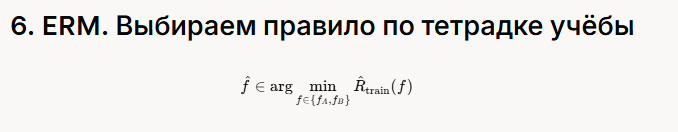

In [103]:
candidates = {"A": f_A, "B": f_B}
train_risks = {name: R_hat(f, X_train, y_train) for name, f in candidates.items()}
best_name = min(train_risks, key=train_risks.get)  # argmin по train
print(train_risks, "выбрали", best_name)           # A=1, B=4/7 → B

{'A': 1.0, 'B': 0.5714285714285714} выбрали B


In [104]:
# В sklearn тот же смысл у fit. Берётся класс моделей и уменьшается train MSE.

In [105]:
# DummyRegressor(strategy="constant", constant=2) ≈ правило A
dummy = DummyRegressor(strategy="constant", constant=2.0)
dummy.fit(X_train.reshape(-1, 1), y_train)  # ERM внутри своего крошечного F
print(mean_squared_error(y_train, dummy.predict(X_train.reshape(-1, 1))))  # 1.0

1.0


In [106]:
# Дерево на одном признаке почти правило B плюс может выучить среднее в листе.

In [107]:
tree = DecisionTreeRegressor(max_depth=1)
tree.fit(X_train.reshape(-1, 1), y_train)  # argmin train MSE по осевым сплитам
print(tree.predict(np.array([[0.0], [1.0]])))
# на этой семёрке: для x=0 все y=1 → лист 1.0
# для x=1 три раза 3 и один 1 → лист (3+3+3+1)/4 = 2.5

[1.  2.5]


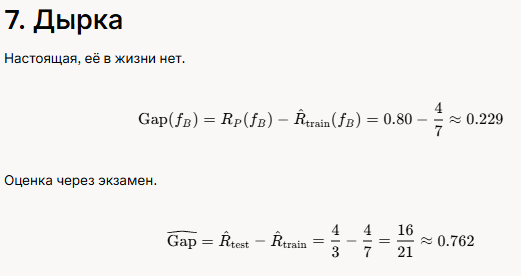

In [108]:
f_hat = f_B
gap_true = risk_P(f_hat) - R_hat(f_hat, X_train, y_train)   # 0.80 - 4/7
gap_hat  = R_hat(f_hat, X_test, y_test) - R_hat(f_hat, X_train, y_train)  # 4/3 - 4/7
print(gap_true, gap_hat)

0.22857142857142865 0.7619047619047619


In [109]:
# fit смотрит только train. Сообщать нужно test. Дырка большая, если тест крошечный, как эти 3 строки.

In [114]:
import numpy as np

# большой мир
# P(y=1|x=0)=0.80, P(y=3|x=0)=0.20, f*(0)=1.4, sigma^2=0.64

def sample_poor(n_poor, rng):
    # тетрадка только бедных домов
    return rng.choice([1.0, 3.0], size=n_poor, p=[0.80, 0.20])

rng = np.random.default_rng(0)
B = 2000
n_poor = 3  # как три бедных в нашей семёрке

preds_const = np.full(B, 2.0)                         # правило A
preds_mean = np.array([sample_poor(n_poor, rng).mean() for _ in range(B)])  # среднее тетрадки

def bias_var(preds, f_star=1.4):
    mean_pred = preds.mean()                           # E[f_hat(0)]
    bias2 = (mean_pred - f_star) ** 2                  # (E f_hat - f*)^2
    var = preds.var()                                  # E[(f_hat - E f_hat)^2]
    noise = 0.64
    err = noise + bias2 + var
    return mean_pred, bias2, var, err

print("A всегда 2 ", bias_var(preds_const))
print("среднее по 3", bias_var(preds_mean))

A всегда 2  (2.0, 0.3600000000000001, 0.0, 1.0)
среднее по 3 (1.4076666666666668, 5.877777777778185e-05, 0.2118078888888889, 0.8518666666666667)


In [115]:
import numpy as np
from sklearn.model_selection import KFold
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_squared_error

X = np.array([0, 1, 0, 1, 1, 0, 1, 0, 1, 0]).reshape(-1, 1)
y = np.array([1, 3, 1, 3, 3, 1, 1, 3, 3, 1], dtype=float)

kf = KFold(n_splits=5, shuffle=False)  # A1..A5 по две строки как выше
fold_risks = []

for train_idx, val_idx in kf.split(X):
    # f^(-k) учится без A_k
    model = DecisionTreeRegressor(max_depth=1)
    model.fit(X[train_idx], y[train_idx])
    # R_{A_k}(f^(-k)) = (1/|A_k|) Σ (f-y)^2
    r_k = mean_squared_error(y[val_idx], model.predict(X[val_idx]))
    fold_risks.append(r_k)

fold_risks = np.array(fold_risks)
R_cv = fold_risks.mean()                              # (1/K) Σ R_{A_k}
SE = fold_risks.std(ddof=1) / np.sqrt(len(fold_risks))  # SE среднего по фолдам
print(fold_risks, R_cv, SE)

# LOOCV это KFold(n_splits=n)
# K = n

[0.25 0.25 0.25 4.   0.25] 1.0 0.75


In [116]:
from sklearn.model_selection import cross_val_score

for d in [1, 2, None]:
    model = DecisionTreeRegressor(max_depth=d)
    # cross_val_score даёт score, для MSE берут neg_mean_squared_error
    scores = cross_val_score(model, X, y, cv=5, scoring="neg_mean_squared_error")
    R_cv = -scores.mean()
    print("depth", d, "R_cv", R_cv)
# победитель по min R_cv склонен быть оптимистичным, это слайд проклятия

depth 1 R_cv 1.0
depth 2 R_cv 1.0
depth None R_cv 1.0


In [117]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

# домики, d=1
X = np.array([[0.], [1.], [0.], [1.]])
y = np.array([1., 3., 1., 3.])

tree = DecisionTreeRegressor(max_depth=1)
tree.fit(X, y)

# порог s, лист слева c_L, лист справа c_R
print("s =", tree.tree_.threshold[0])          # 0.5
print("f(0), f(1) =", tree.predict([[0.], [1.]]))  # 1 и 3

# руками та же формула
# f(x) = 1*{x<=0.5} + 3*{x>0.5}
def f_hat(x):
    return np.where(x <= 0.5, 1.0, 3.0)

print(f_hat(np.array([0., 1.])))

s = 0.5
f(0), f(1) = [1. 3.]
[1. 3.]


In [118]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor

# лист R4 со слайда: 2, 5, 1
counts = np.array([2, 5, 1])
N = counts.sum()                          # 8
p = counts / N                            # 0.250, 0.625, 0.125
k = np.argmax(p) + 1                      # класс 2, нумерация с 1
gini = 1 - np.sum(p ** 2)                 # 1 - 0.0625 - 0.390625 - 0.015625 = 0.53125
print(p, k, gini)

# таблица слайда: родитель 6/2, левый 4/0, правый 2/2
def gini(n1, n0):
    n = n1 + n0
    p1, p0 = n1 / n, n0 / n
    return 1 - p1 ** 2 - p0 ** 2

def mis(n1, n0):
    return 1 - max(n1, n0) / (n1 + n0)

# Gain = Q(parent) - (N_L/N) Q_L - (N_R/N) Q_R
print("mis gain", 0.25 - (4/8)*0 - (4/8)*0.5)          # 0
print("gini gain", gini(6, 2) - (4/8)*gini(4, 0) - (4/8)*gini(2, 2))  # 0.125

# регрессия домиков, SSE, порог 5
X = np.array([[1.], [2.], [8.], [9.]])
y = np.array([1., 1., 3., 3.])
reg = DecisionTreeRegressor(max_depth=1)
reg.fit(X, y)
print(reg.tree_.threshold[0], reg.predict(X))  # 5.0 и [1, 1, 3, 3]

[0.25  0.625 0.125] 2 0.53125
mis gain 0.0
gini gain 0.125
5.0 [1. 1. 3. 3.]


In [119]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

x = np.array([1., 2., 8., 9.])
y = np.array([0, 0, 1, 1])

order = np.argsort(x)
xs, ys = x[order], y[order]
different = xs[1:] != xs[:-1]
thresholds = ((xs[1:] + xs[:-1]) / 2)[different]   # 1.5, 5.0, 8.5
print(thresholds)

def Q(s):
    left = ys[xs <= s]
    right = ys[xs > s]
    def H(side):
        if len(side) == 0:
            return 0.0
        p1 = side.mean()          # доля класса 1
        return 1 - (1 - p1) ** 2 - p1 ** 2
    n = len(ys)
    return (len(left) / n) * H(left) + (len(right) / n) * H(right)

for s in thresholds:
    print(s, Q(s))                # 1.5 → 0.333, 5 → 0, 8.5 → 0.333

tree = DecisionTreeClassifier(max_depth=1)
tree.fit(x.reshape(-1, 1), y)
print(tree.tree_.threshold[0], tree.predict(x.reshape(-1, 1)))  # 5.0 и [0, 0, 1, 1]

[1.5 5.  8.5]
1.5 0.3333333333333333
5.0 0.0
8.5 0.33333333333333326
5.0 [0 0 1 1]


In [121]:
import numpy as np
from sklearn.tree import DecisionTreeClassifier

X = np.array([[1.], [2.], [8.], [9.]])
y = np.array([0, 0, 1, 1])

# pre-pruning, те же стопы
for kwargs in [
    dict(max_depth=1),
    dict(min_samples_split=5),
    dict(min_samples_leaf=3),
]:
    tree = DecisionTreeClassifier(**kwargs)
    tree.fit(X, y)
    print(kwargs, "depth", tree.get_depth(), "leaves", tree.get_n_leaves())

# post-pruning: большое дерево, потом ccp_alpha
# на этих 4 точках дерево и так крошечное, путь почти пустой
big = DecisionTreeClassifier(random_state=0)
path = big.cost_complexity_pruning_path(X, y)
print("alphas", path.ccp_alphas)   # последовательность штрафа за лист

{'max_depth': 1} depth 1 leaves 2
{'min_samples_split': 5} depth 0 leaves 1
{'min_samples_leaf': 3} depth 0 leaves 1
alphas [0.  0.5]


In [122]:
import numpy as np
from math import comb

x = np.array([1, 2, 3, 4, 5, 6, 7, 8], dtype=float)
y = np.array([0, 0, 0, 0, 1, 1, 1, 1])

def T(y_perm):
    return abs(x[y_perm == 1].mean() - x[y_perm == 0].mean())

T_obs = T(y)                       # 4.0
print("T_obs", T_obs)
print("перестановок", comb(8, 4))  # 70

# одна перестановка со слайда
y1 = np.array([0, 1, 0, 1, 1, 0, 1, 0])
print("T1", T(y1))                 # 0.0

# категориальный с K буквами: кандидатов 2^(K-1) - 1
for K in (2, 20):
    print(K, 2 ** (K - 1) - 1)     # 1 и 524287

T_obs 4.0
перестановок 70
T1 0.0
2 1
20 524287


In [124]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import BaggingRegressor

rng = np.random.default_rng(0)
# один признак, правдa 2*x, шум
x = np.linspace(0, 1, 40)
y = 2 * x + rng.normal(0, 0.3, size=40)
X = x.reshape(-1, 1)

# три бутстрапа руками
preds = []
for b in range(3):
    idx = rng.choice(40, size=40, replace=True)   # S^{(b)}
    tree = DecisionTreeRegressor().fit(X[idx], y[idx])
    preds.append(tree.predict([[0.5]])[0])
print(preds, np.mean(preds))                       # f_bag(0.5)

# B=10, как в задании 10.3
bag = BaggingRegressor(DecisionTreeRegressor(), n_estimators=10, random_state=0)
bag.fit(X, y)
print(bag.predict([[0.5]])[0])                     # (1/B) Σ f^{(b)}(0.5)

[0.9870806267578153, 1.2871129851917775, 1.2871129851917775] 1.1871021990471233
1.2571097493483814


In [125]:
import numpy as np
from sklearn.ensemble import RandomForestRegressor

rng = np.random.default_rng(0)
n = 40
X = rng.normal(size=(n, 4))
y = X[:, 0] + rng.normal(scale=0.3, size=n)

# m = p/3 руками: 4 признака, в узле 1 или 2
rf = RandomForestRegressor(
    n_estimators=50,
    max_features=1 / 3,    # не дефолт регрессора, тот берёт все
    oob_score=True,
    random_state=0,
)
rf.fit(X, y)
print("OOB R^2", rf.oob_score_)
print("MDI", rf.feature_importances_)   # столбец 0 должен быть самым тяжёлым

# доля строк вне одной тетрадки
print((1 - 1 / n) ** n)                  # около 0.36

OOB R^2 0.4982064051191377
MDI [0.44569856 0.18490991 0.1839554  0.18543613]
0.36323243988788034


In [126]:
import numpy as np
from sklearn.ensemble import ExtraTreesClassifier, RandomForestClassifier

X = np.array([[1.], [2.], [8.], [9.]])
y = np.array([0, 0, 1, 1])

# один случайный порог на отрезке [min, max] = [1, 9]
rng = np.random.default_rng(0)
s = rng.uniform(1, 9)
print("случайный порог", s)

et = ExtraTreesClassifier(n_estimators=20, max_features=1, random_state=0)
et.fit(X, y)
print(et.predict(X))   # голосование 20 деревьев со случайными порогами

rf = RandomForestClassifier(n_estimators=20, max_features=1, random_state=0)
rf.fit(X, y)
print(rf.predict(X))   # те же 4 точки, но порог в каждом узле лучший

случайный порог 6.0956934985716344
[0 0 1 1]
[0 0 1 1]


In [128]:
import numpy as np
from sklearn.tree import DecisionTreeRegressor

X = np.array([[1.], [2.], [8.], [9.]])
y = np.array([0., 0., 1., 1.])

tree = DecisionTreeRegressor(max_depth=1).fit(X, y)
# apply даёт номер листа, это и есть какой φ_m(x) = 1
print(tree.apply(X))                 # две группы, два индикатора
print(tree.predict(X))               # c_m горящего листа

# два дерева, ответ = среднее, то есть сумма θ
rng = np.random.default_rng(0)
preds = []
for b in range(2):
    idx = rng.choice(4, size=4, replace=True)
    t = DecisionTreeRegressor(max_depth=1).fit(X[idx], y[idx])
    preds.append(t.predict(X))
print(np.mean(preds, axis=0))        # (1/B) Σ_b Σ_m c_m^{(b)} φ_m^{(b)}(x)

[1 1 2 2]
[0. 0. 1. 1.]
[0.  0.  0.5 0.5]
